# Comparing tTEM with tTEM

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from anemone.experiment import *
from anemone.inversion  import *
from anemone.forwards import *

In [3]:
gpu = torch.device('cpu')
cmdl = FewLayerModel.starting_model(3)

In [4]:
tx = Loop.square(3)
rx = Receiver(x=13)

In [5]:
tgates = torch.logspace(-5, -3, 21)

recfilters = FilterChain([
    ButterworthFilter(6.79e5),
])

device = torch.device('cpu')
fwr = Forward(tx, rx, tgates, Waveform.example(), recfilters, tolerance=1e-5)

\\bubi4.uni.au.dk\people\matt.griffiths\_git\anemone\src\anemone\experiment\experiment.py:125: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [6]:
res = np.array([10, 200, 20])
thick1 = np.linspace(0.1, 5, 25)

In [7]:
sigma = torch.from_numpy(1./res)
thick = torch.tensor([5, 10])
data = fwr(sigma, thick)

In [9]:
thick_stack = np.vstack([thick1, np.ones_like(thick1)*10])
sigma = torch.from_numpy(1./res)[:, None]
thick = torch.from_numpy(thick_stack)

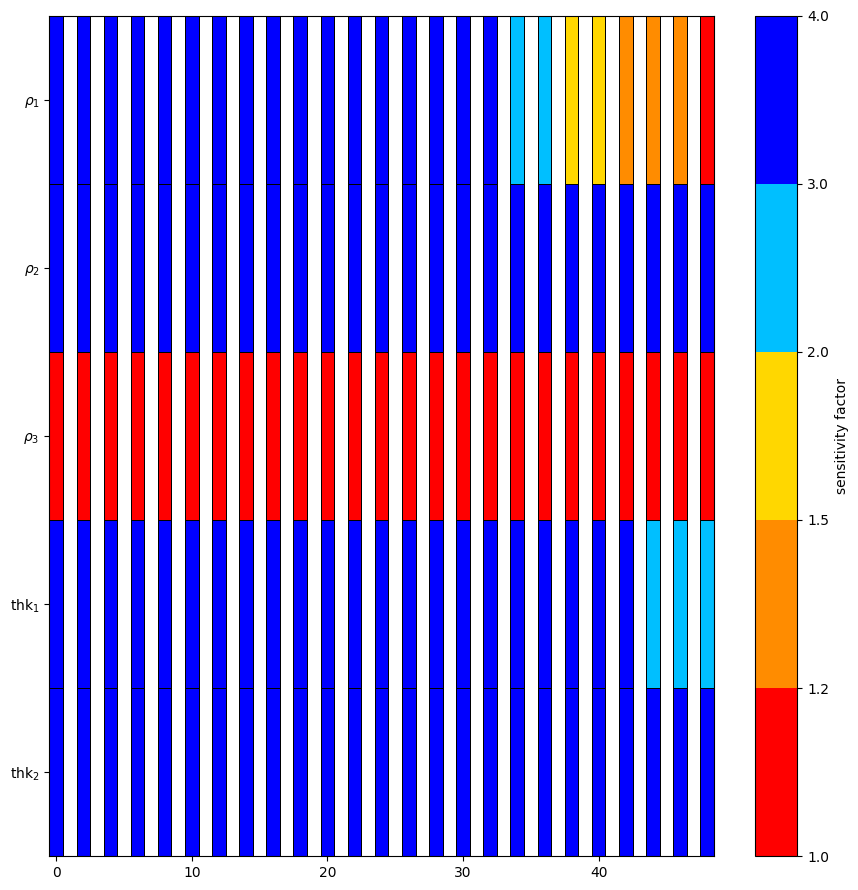

In [12]:
cm = plt.get_cmap('Spectral')

fig,axs = plt.subplots(1,1, sharex=True, figsize=(9,9))

for i,thk in enumerate(thick1):
    sigma = torch.from_numpy(1./res)
    thick = torch.tensor([thk, 10])
    dbdt = fwr(sigma, thick)
    dbdt_err = compute_relstd(tgates, dbdt, moment=3*9)

    m_true = FewLayerModel(sigma, thick)
    inv = Inversion(dbdt, dbdt*dbdt_err, m_true, fwr, data_transform=torch.log10)
    inv.plot_sensitivity_analysis(ax=axs, x_offset=i*2, cbar=i==2)

    cmd_smooth = SmoothModel.starting_model(31)    
    dbdt_with_noise = torch.abs(dbdt + torch.randn(len(dbdt))*dbdt*dbdt_err)


    inv2 = Inversion(dbdt_with_noise, dbdt*dbdt_err, cmd_smooth, fwr, logger=print, data_transform=torch.log10)
    
axs.set_ylim(5,0)

plt.tight_layout()